**Human bold text Activity Recognition (Multi-Class Classification) with TensorFlow / Keras**

**Dataset:** UCI HAR · 561 features · 6 classes · [link](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones)

**Classes (activities):**
Walking · Walking Upstairs · Walking Downstairs · Sitting · Standing · Laying

**Pipeline:**
Load → EDA → Split → Scale → Train → Evaluate

**Multiclass:**
Softmax · Sparse Cross-Entropy · Argmax

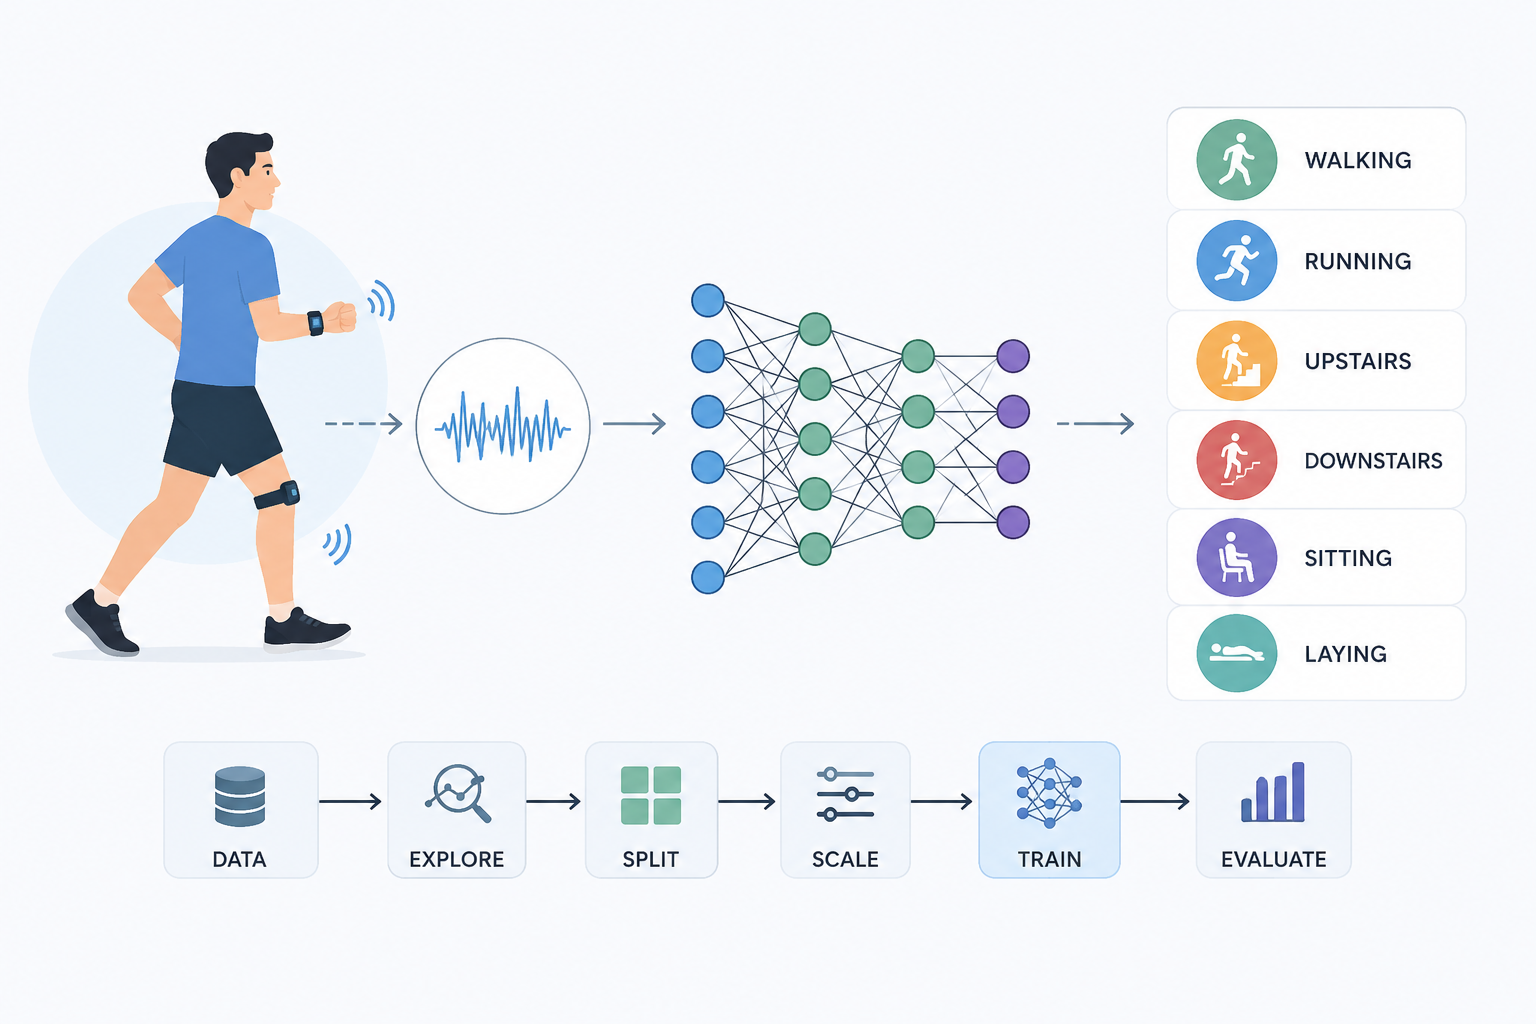

## **1. Imports & Setup**

In [ ]:
import urllib.request
import zipfile
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

In [ ]:
# seeding for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# configuration
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

## **2. Load the UCI HAR Dataset**

In [ ]:
# step 1 - download the daatset zip file
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip"
urllib.request.urlretrieve(url, "dataset.zip")

# step 2 - unzip it into current folder
with zipfile.ZipFile("dataset.zip") as z:
  z.extractall(".")

print("Dataset ready")

Dataset ready


In [ ]:
# load the training data
X_train_full = pd.read_csv("/content/UCI HAR Dataset/train/X_train.txt", header=None, sep=r"\s+")
y_train_full = pd.read_csv("/content/UCI HAR Dataset/train/y_train.txt", header=None, sep=r"\s+")

# load the test data
X_test_raw = pd.read_csv("/content/UCI HAR Dataset/test/X_test.txt", header=None, sep=r"\s+")
y_test = pd.read_csv("/content/UCI HAR Dataset/test/y_test.txt", header=None, sep=r"\s+")

# load the subject ID (which person)
subjects = pd.read_csv("/content/UCI HAR Dataset/train/subject_train.txt", header=None, sep=r"\s+").values.ravel()

In [ ]:
X_train_full.head()

,0,1,2,3,4,5,6,7,8,9,...,551,552,553,554,555,556,557,558,559,560
0,0.289,-0.020,-0.133,-0.995,-0.983,-0.914,-0.995,-0.983,-0.924,-0.935,...,-0.074,-0.299,-0.710,-0.113,0.030,-0.465,-0.018,-0.841,0.180,-0.059
1,0.278,-0.016,-0.124,-0.998,-0.975,-0.960,-0.999,-0.975,-0.958,-0.943,...,0.158,-0.595,-0.861,0.053,-0.007,-0.733,0.704,-0.845,0.180,-0.054
2,0.280,-0.019,-0.113,-0.995,-0.967,-0.979,-0.997,-0.964,-0.977,-0.939,...,0.415,-0.391,-0.760,-0.119,0.178,0.101,0.809,-0.849,0.181,-0.049
3,0.279,-0.026,-0.123,-0.996,-0.983,-0.991,-0.997,-0.983,-0.989,-0.939,...,0.405,-0.117,-0.483,-0.037,-0.013,0.640,-0.485,-0.849,0.182,-0.048
4,0.277,-0.017,-0.115,-0.998,-0.981,-0.990,-0.998,-0.980,-0.990,-0.942,...,0.088,-0.351,-0.699,0.123,0.123,0.694,-0.616,-0.848,0.185,-0.044


In [ ]:
y_train_full.head()

,0
0,5
1,5
2,5
3,5
4,5


## **3. Quick Exploration**

In [ ]:
print(X_train_full.shape)
print(y_train_full.shape)

(7352, 561)
(7352, 1)


In [ ]:
print(X_test_raw.shape)
print(y_test.shape)

(2947, 561)
(2947, 1)


In [ ]:
# flatten labels to 1D and shift from 1-6 to 0-5 for keras
y_train_full = np.asarray(y_train_full).ravel()
y_test = np.asarray(y_test).ravel()

print("Unique labels before shift:", np.unique(y_train_full))

y_train_full = y_train_full - 1
y_test = y_test - 1

print("Unique labels after shift:", np.unique(y_train_full))

Unique labels before shift: [1 2 3 4 5 6]
Unique labels after shift: [0 1 2 3 4 5]


In [ ]:
CLASS_NAMES = ["Walking", "Walking Up", "Walking Down", "Sitting", "Standing", "Laying"]
N_CLASSES = len(CLASS_NAMES)

print(CLASS_NAMES)
print(N_CLASSES)

['Walking', 'Walking Up', 'Walking Down', 'Sitting', 'Standing', 'Laying']
6


**Class Mapping**

`0` Walking · `1` Walking Upstairs · `2` Walking Downstairs · `3` Sitting · `4` Standing · `5` Laying

*(Original files use 1–6; we shifted to 0–5 for Keras.)*

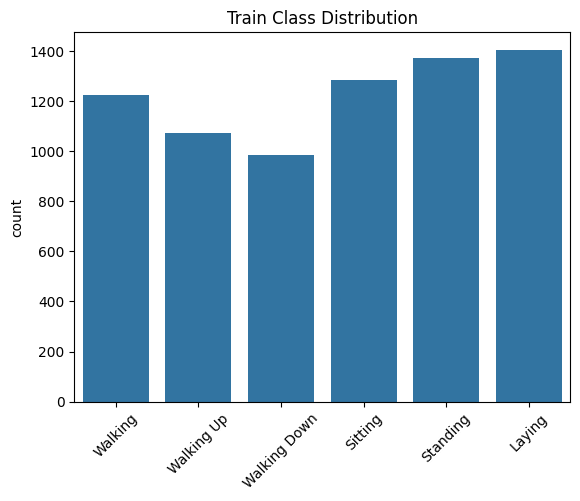

In [ ]:
# class distribution
sns.countplot(x=y_train_full)
plt.title("Train Class Distribution")
plt.xticks(ticks=range(6), labels=CLASS_NAMES, rotation=45)
plt.show()

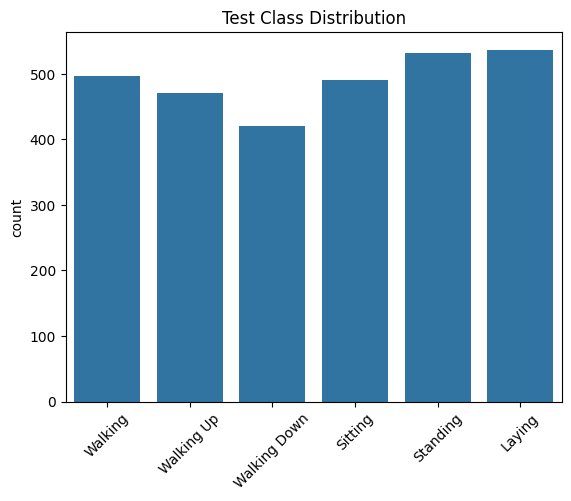

In [ ]:
sns.countplot(x=y_test)
plt.title("Test Class Distribution")
plt.xticks(ticks=range(6), labels=CLASS_NAMES, rotation=45)
plt.show()

>**Insight:** Good balance overall

## **4. Train / Validation Split (by subject)**

Each row comes from a **person** (a subject). Windows from the same person look very similar,
so a random split would put the same person in both train and validation —
the model would "cheat" and validation accuracy would look better than it really is.

**Fix:** split by *subject*, so no person appears in both sets.
(The official test set already uses different subjects — that's why we do the same here.)

In [ ]:
# split using GSS
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_idx, val_idx = next(gss.split(X_train_full, y_train_full, groups=subjects))

X_train, X_val = X_train_full.iloc[train_idx], X_train_full.iloc[val_idx]
y_train, y_val = y_train_full[train_idx], y_train_full[val_idx]

print("Train:", X_train.shape, "  labels:", y_train.shape)
print("Val:  ", X_val.shape,   "  labels:", y_val.shape)
print("Test: ", X_test_raw.shape, "  labels:", y_test.shape)

Train: (5551, 561)   labels: (5551,)
Val:   (1801, 561)   labels: (1801,)
Test:  (2947, 561)   labels: (2947,)


In [ ]:
# sanity check: no subject overlap between train and validation
print("Subjects in both sets:", set(subjects[train_idx]) & set(subjects[val_idx]))

Subjects in both sets: set()


## **5. Feature Scaling**

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test_raw)

print("Train mean ≈0, std ≈1:", X_train.mean().round(3), X_train.std().round(3))

Train mean ≈0, std ≈1: 0.0 1.0


## **6. Build the Neural Network**

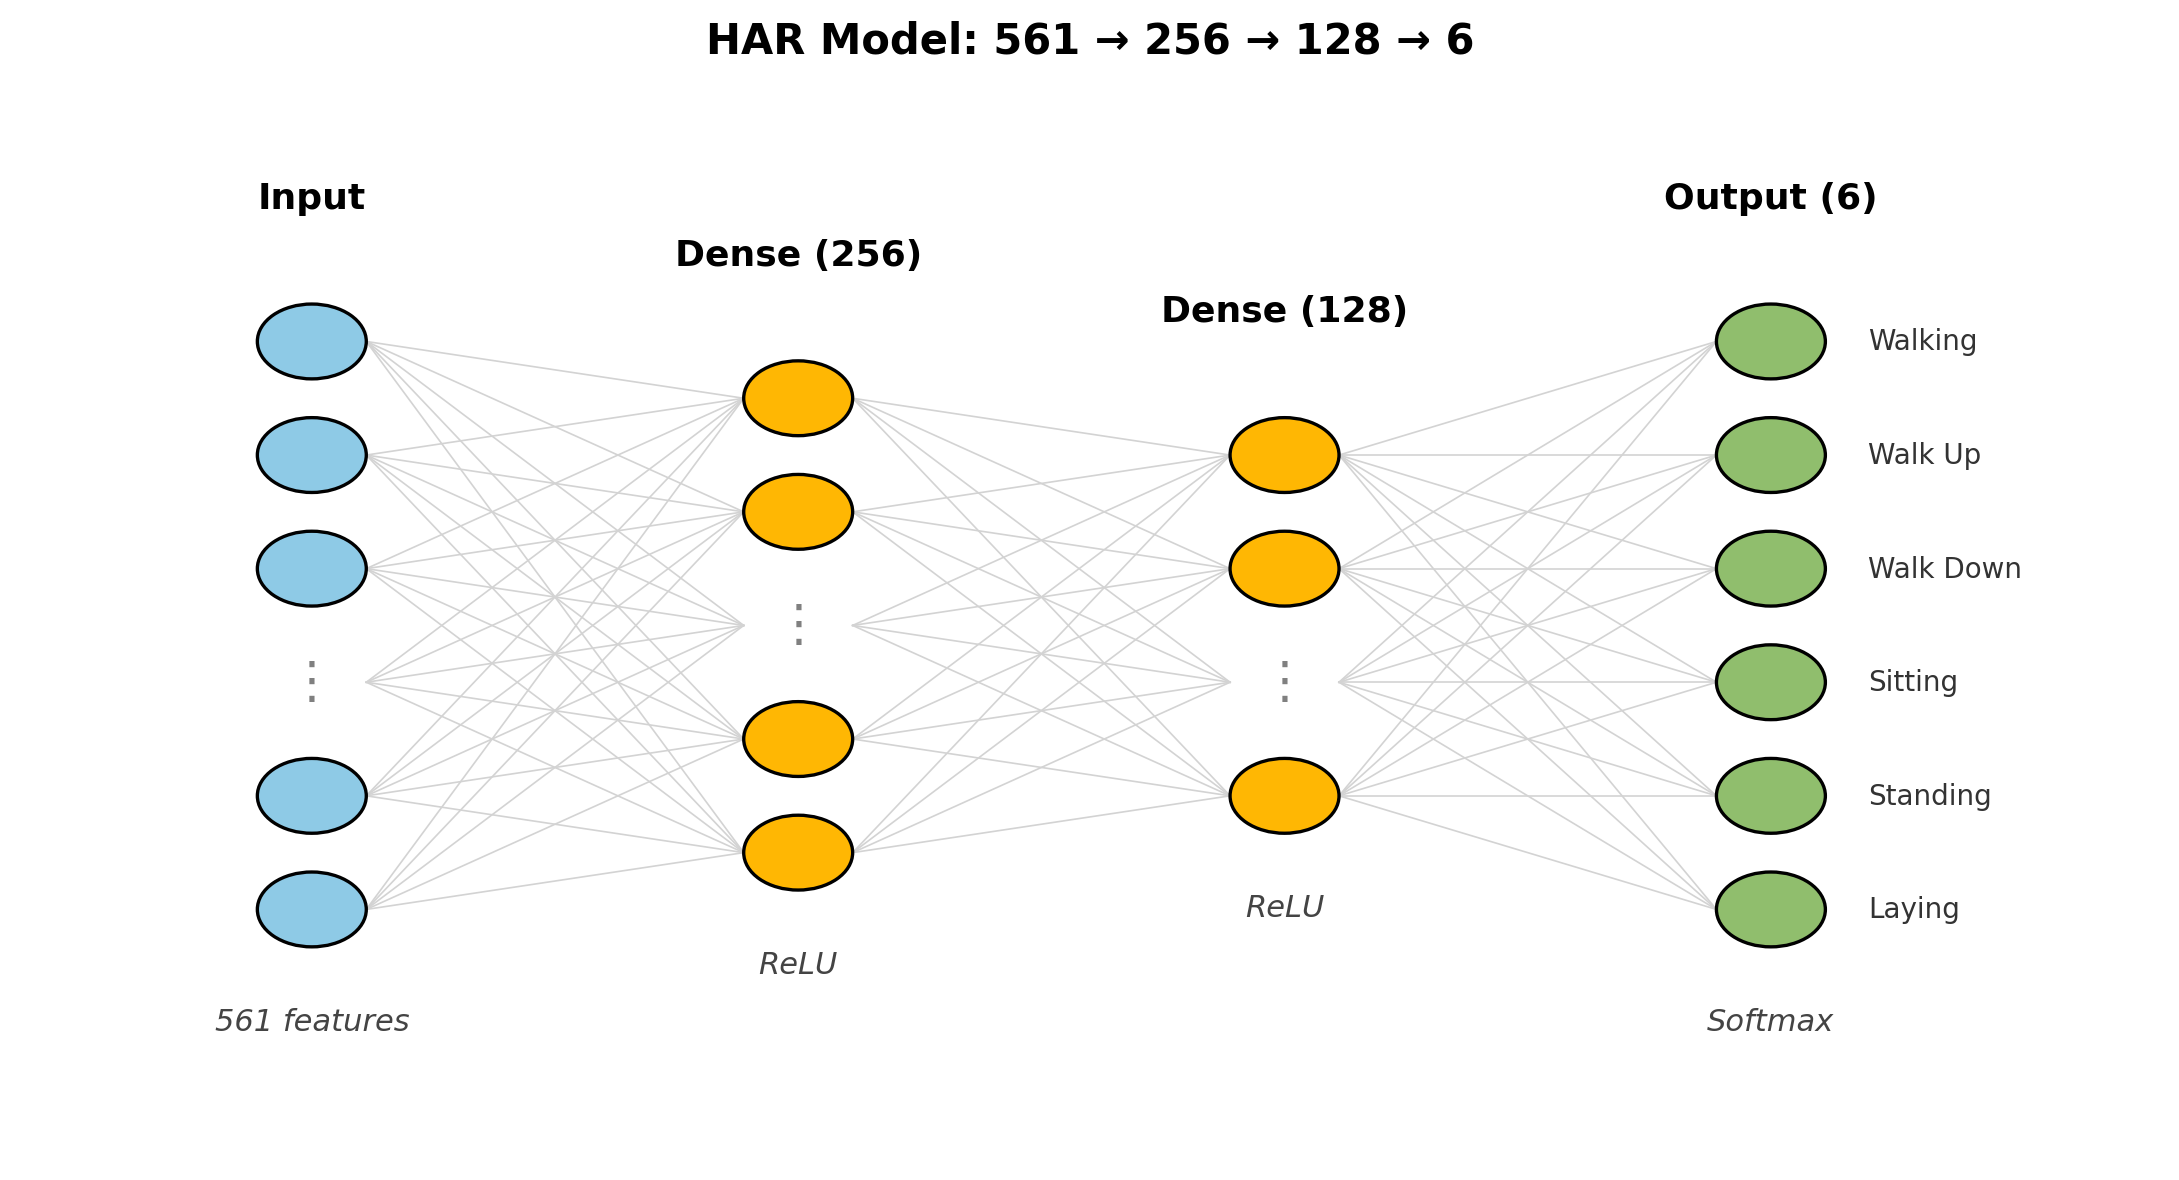

In [ ]:
model = keras.Sequential([
    # input layer
    keras.Input(shape=(X_train.shape[1], )),

    # hidden layer 1
    keras.layers.Dense(
        units=256,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),
    keras.layers.Dropout(0.3),

    # hidden layer 2
    keras.layers.Dense(
        units=128,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.001)
    ),
    keras.layers.Dropout(0.3),

    # output layer
    keras.layers.Dense(
        units=N_CLASSES,
        activation="softmax"
    )

])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       143,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177,542 (693.52 KB)

 Trainable params: 177,542 (693.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",     # if labels are one-hot encoded use categorical_crossentropy
    metrics=["accuracy"]
)

**7. Training the Neural Network**

In [ ]:
# configuring early stopping for the model
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

print(f"\nTrained for {len(history.history['loss'])} epochs")

Epoch 1/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8108 - loss: 0.9936 - val_accuracy: 0.9295 - val_loss: 0.7145
Epoch 2/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9252 - loss: 0.6777 - val_accuracy: 0.9423 - val_loss: 0.6254
Epoch 3/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9501 - loss: 0.5788 - val_accuracy: 0.9500 - val_loss: 0.5626
Epoch 4/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9580 - loss: 0.5177 - val_accuracy: 0.9439 - val_loss: 0.5582
Epoch 5/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9645 - loss: 0.4647 - val_accuracy: 0.9606 - val_loss: 0.4552
Epoch 6/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9687 - loss: 0.4278 - val_accuracy: 0.9489 - val_loss: 0.4721
Epoch 7/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9690 - loss: 0.3878 - val_accuracy: 0.9495 - val_loss: 0.4480
Epoch 8/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9751 - loss: 0.3484 - val_accuracy: 0.9467 - 

## **8. Learning Curves**

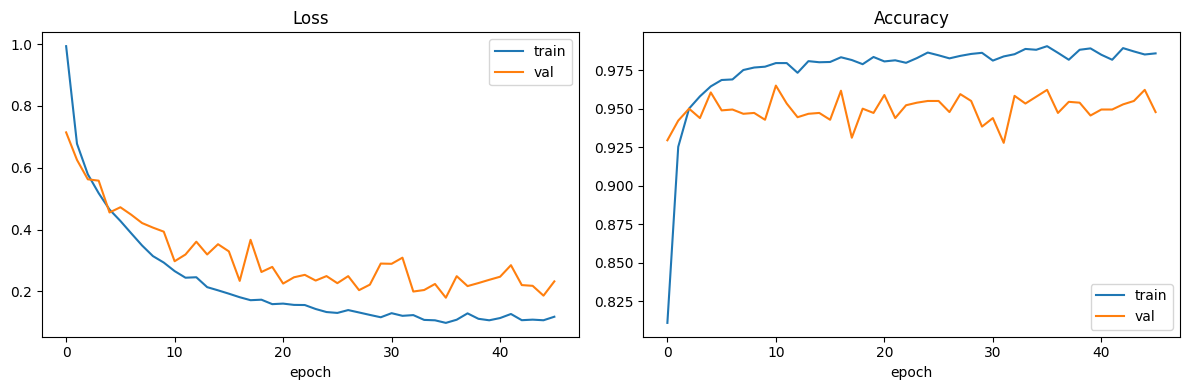

In [ ]:
hist = history.history

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist["loss"],     label="train")
axes[0].plot(hist["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()

axes[1].plot(hist["accuracy"],     label="train")
axes[1].plot(hist["val_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()

plt.tight_layout()
plt.show()

## **9. Evaluation**

In [ ]:
# evaluation on test data
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss:     0.2463
Test accuracy: 0.9488


In [ ]:
# getting the prediction on test data
y_proba = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_proba, axis=1)

print("Softmax output shape:", y_proba.shape)
print(y_proba[:3])
print(y_pred[:3])

Softmax output shape: (2947, 6)
[[0.00000896 0.00004045 0.00000941 0.00010011 0.9998348  0.00000648]
 [0.00058438 0.00158018 0.00129261 0.06555375 0.93012285 0.00086615]
 [0.000204   0.00033719 0.00012659 0.00301504 0.99622244 0.00009469]]
[4 4 4]


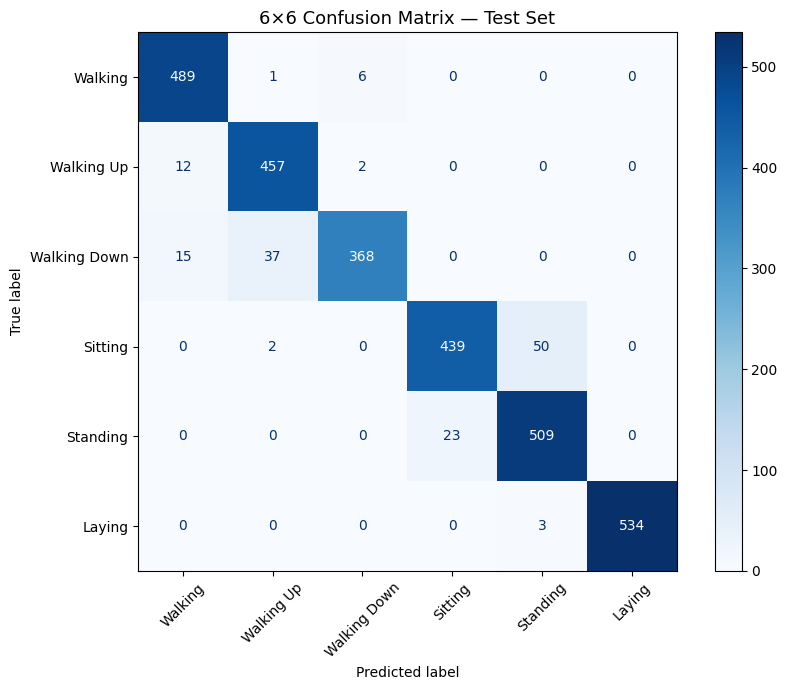


Row = Actual class, Column = Predicted class


In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(ax=ax, cmap="Blues", colorbar=True, xticks_rotation=45)
ax.set_title("6×6 Confusion Matrix — Test Set", fontsize=13)
plt.tight_layout()
plt.show()

print("\nRow = Actual class, Column = Predicted class")

In [ ]:
# classification report
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

     Walking     0.9477    0.9859    0.9664       496
  Walking Up     0.9195    0.9703    0.9442       471
Walking Down     0.9787    0.8762    0.9246       420
     Sitting     0.9502    0.8941    0.9213       491
    Standing     0.9057    0.9568    0.9305       532
      Laying     1.0000    0.9944    0.9972       537

    accuracy                         0.9488      2947
   macro avg     0.9503    0.9463    0.9474      2947
weighted avg     0.9500    0.9488    0.9485      2947



## **10. Saving the model and scaler**

In [ ]:
# save the model
model.save("har_model.keras")

# save the scaler using joblib
joblib.dump(scaler, "har_scaler.joblib")

print("Model and Scaler saved!")

Model and Scaler saved!


## **11. Loading the model and predicting on new data points**

In [ ]:
# load the scaler and model back
loaded_model = keras.models.load_model("/content/har_model.keras")
loaded_scaler = joblib.load("/content/har_scaler.joblib")

print("Model and scaler loaded!")

Model and scaler loaded!


In [ ]:
CLASS_NAMES = ["Walking", "Walking Up", "Walking Down", "Sitting", "Standing", "Laying"]


def get_prediction(input_data):
  """Predict the activity for ONE new data point (561 raw feature values)."""

  # step 1: reshape the data as per the scaler requirement (1, 561)
  input_data = np.asarray(input_data).reshape(1, -1)

  # step 2: scale the data
  input_data_scaled = loaded_scaler.transform(input_data)

  # step 3: get the softmax probability values and apply argmax
  probs = loaded_model.predict(input_data_scaled, verbose=0)
  class_id = np.argmax(probs)

  return CLASS_NAMES[class_id]

In [ ]:
print(X_test_raw.iloc[0])
print(y_test[0])

pred = get_prediction(X_test_raw.iloc[0])
print(pred)

0      0.257
1     -0.023
2     -0.015
3     -0.938
4     -0.920
       ...  
556   -0.826
557    0.271
558   -0.720
559    0.277
560   -0.058
Name: 0, Length: 561, dtype: float64
4
Standing


In [ ]:
# try it on a few rows from the raw (unscaled) test data
for i in [0, 100, 500]:
    predicted = get_prediction(X_test_raw.iloc[i])
    actual = CLASS_NAMES[y_test[i]]
    print(f"Row {i:>3} | Predicted: {predicted:<14} | Actual: {actual}")

Row   0 | Predicted: Standing       | Actual: Standing
Row 100 | Predicted: Walking        | Actual: Walking
Row 500 | Predicted: Sitting        | Actual: Sitting


## **12. Wrap Up**

### What we did

1. **Loaded** the UCI HAR dataset — 561 sensor features, 6 activities
2. **Explored** the class distribution (nicely balanced)
3. **Split** train/validation **by subject** — so the model never "sees" a validation person during training
4. **Scaled** the features with `StandardScaler` (fit on train only!)
5. **Built** a simple neural network: Dense(256) → Dense(128) → Softmax(6), with Dropout + L2
6. **Trained** with Adam + sparse cross-entropy + early stopping
7. **Evaluated** with accuracy, a 6×6 confusion matrix, and a classification report
8. **Saved** the model + scaler and built a `get_prediction()` function for new data

### Key takeaways

- **Softmax + argmax** is the standard recipe for multiclass classification
- **Sparse** categorical cross-entropy works with plain integer labels (0–5) — no one-hot needed
- Most confusion happens between **Sitting** and **Standing** — the sensors see them very similarly
- Always save the **scaler** with the model — preprocessing is part of the model!

### Try it yourself

- Change the number of hidden units or layers — does accuracy improve?
- Try a different dropout rate (0.1, 0.5) and watch the learning curves
- Replace `StandardScaler` with `MinMaxScaler` and compare
